# Sensitivity Analysis of template project

In [ ]:
from uq_physicell.model_analysis import calculate_qoi_statistics
import warnings
warnings.filterwarnings('ignore')  # Suppress all warnings for cleaner output

db_file = 'ex9_Simulations.db'
qoi_funcs = {
    'live_cell_count': lambda df: len( df[ df['dead'] == False ]),
    'dead_cell_count': lambda df: len( df[ df['dead'] == True ]),
    'integrated_dead_cell_count': lambda mcds_ts: sum(map(lambda mcds: len(mcds.get_cell_df()[mcds.get_cell_df()['dead'] == True]), mcds_ts))     
}

# Calculate the QoIs based on the qoi_funcs define (retunr summary based on mean across replicates and relative Monte Carlo standard error: sigma/[mean*sqrt(num_replicates)])
df_mean_qois, df_mean_std, df_relative_mcse = calculate_qoi_statistics(db_file, qoi_funcs)
display(df_mean_qois)

No QoI data provided, calculating QoIs from the database...
All samples in Samples table have corresponding entries in Output table.
Calculating QoIs from mcds list...


live_cell_count  dead_cell_count  integrated_dead_cell_count
SampleID time                                                                
0        0.0               511.0              0.0                         NaN
         240.0             591.4              5.6                         NaN
         480.0             635.2             13.8                         NaN
         720.0             669.8             17.8                         NaN
         960.0             709.4             20.0                         NaN
...                          ...              ...                         ...
191      6240.0           1861.4             58.4                         NaN
         6480.0           1925.2             64.4                         NaN
         6720.0           1998.4             68.0                         NaN
         6960.0           2070.0             69.0                         NaN
         7200.0           2144.6             73.0                      1210.8

[5952 rows x 3 columns]

## Plot the summary stats and relative Monte Carlo Standard Error (MCSE)

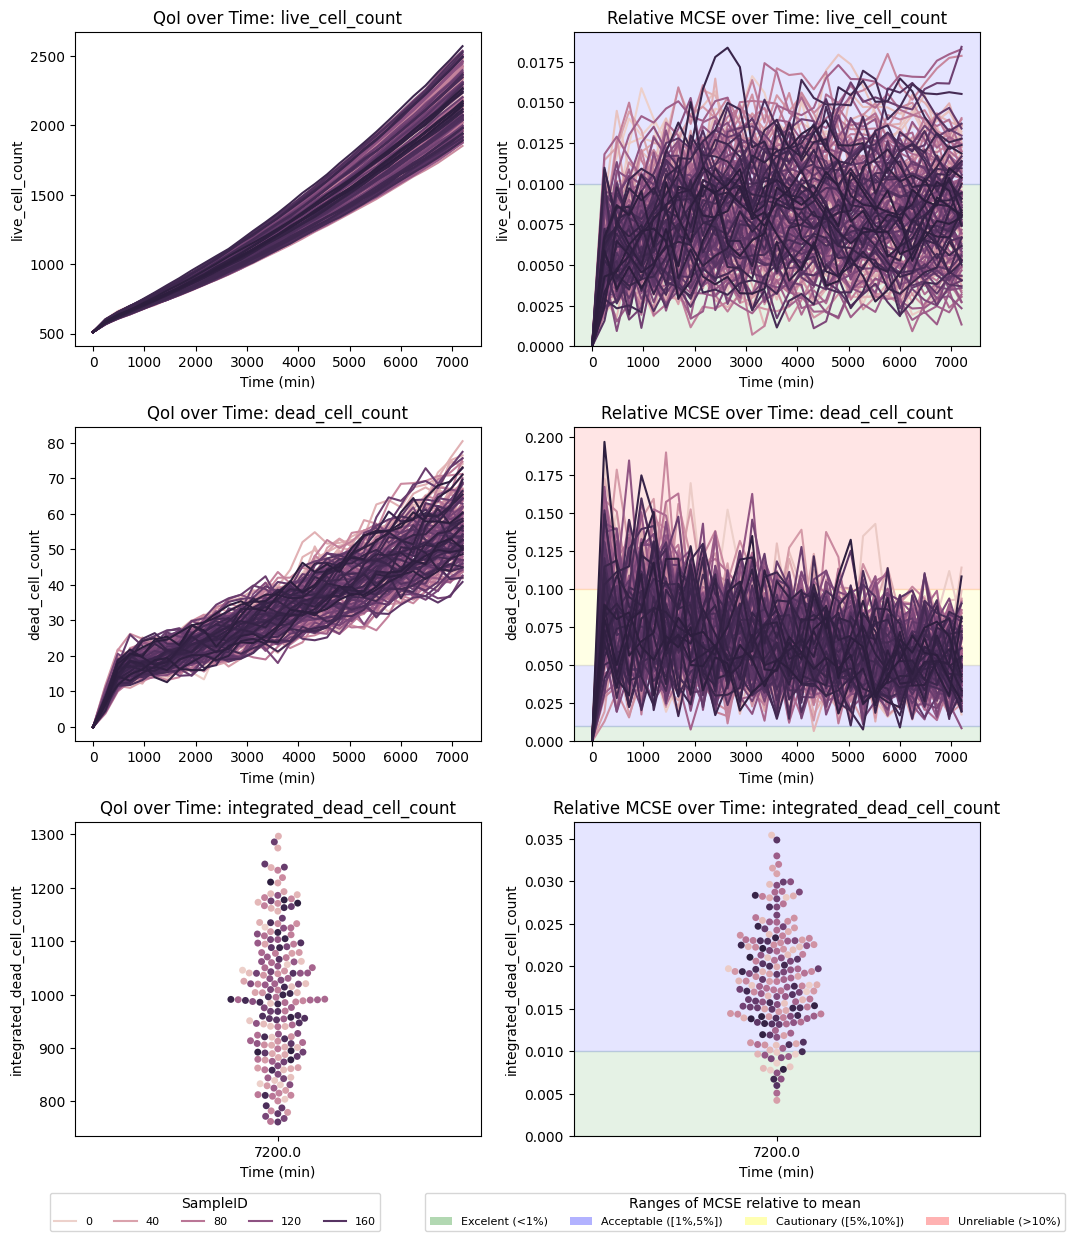

In [2]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.legend import Legend
from uq_physicell.model_analysis import plot_qoi_over_time, get_mcse_legend_handles

fig, axes = plt.subplots(len(qoi_funcs.keys()), 2, figsize=(10, 4*len(qoi_funcs.keys())))
for ax_id, qoi_name in enumerate(qoi_funcs.keys()):
     # Plot QoI time series
    plot_qoi_over_time(df_mean_qois, qoi_name, axes[ax_id,0], show_legend=False)
    axes[ax_id,0].set_title(f"QoI over Time: {qoi_name}")
    # Plot mcse
    plot_qoi_over_time(df_relative_mcse, qoi_name, axes[ax_id,1], plot_mcse_range=True, show_legend=False)
    axes[ax_id,1].set_title(f"Relative MCSE over Time: {qoi_name}")

# Collect SampleID legend handles from left column only
sampleid_handles = {}
for ax_id, ax_row in enumerate(axes):
    ax = ax_row[0]  # Left column (SampleID)
    h, l = ax.get_legend_handles_labels()
    for handle, label in zip(h, l):
        if label not in sampleid_handles:
            sampleid_handles[label] = handle

# Create SampleID legend on the left
sampleid_handles_list = list(sampleid_handles.values())
sampleid_labels_list = list(sampleid_handles.keys())
legend1 = fig.legend(sampleid_handles_list, sampleid_labels_list, 
                     loc='lower center', ncol=6, 
                     bbox_to_anchor=(0.22, -0.035),
                     title='SampleID', frameon=True, fontsize=8)

# Create MCSE ranges legend on the right
mcse_ranges = get_mcse_legend_handles()
legend2 = fig.legend(mcse_ranges, [p.get_label() for p in mcse_ranges],
                     loc='lower center', ncol=5,
                     bbox_to_anchor=(0.75, -0.035),
                     title='Ranges of MCSE relative to mean', frameon=True, fontsize=8)

# Ensure proper layout and save the figure
plt.tight_layout()  # This will automatically adjust spacing to prevent overlaps
plt.savefig('QoI_TimeSeries_and_MCSE.svg', format='svg')

## Sensitivity Analysis from `cell_cycle_entry` and `apoptosis_rate` relative to population of live and dead cells.

Running sensitivity analysis with method: Sobol Sensitivity Analysis
Running Sobol Sensitivity Analysis for QoI: live_cell_count and time: 0.0
Running Sobol Sensitivity Analysis for QoI: live_cell_count and time: 240.0
Running Sobol Sensitivity Analysis for QoI: live_cell_count and time: 480.0
Running Sobol Sensitivity Analysis for QoI: live_cell_count and time: 720.0
Running Sobol Sensitivity Analysis for QoI: live_cell_count and time: 960.0
Running Sobol Sensitivity Analysis for QoI: live_cell_count and time: 1200.0
Running Sobol Sensitivity Analysis for QoI: live_cell_count and time: 1440.0
Running Sobol Sensitivity Analysis for QoI: live_cell_count and time: 1680.0
Running Sobol Sensitivity Analysis for QoI: live_cell_count and time: 1920.0
Running Sobol Sensitivity Analysis for QoI: live_cell_count and time: 2160.0
Running Sobol Sensitivity Analysis for QoI: live_cell_count and time: 2400.0
Running Sobol Sensitivity Analysis for QoI: live_cell_count and time: 2640.0
Running Sobol 

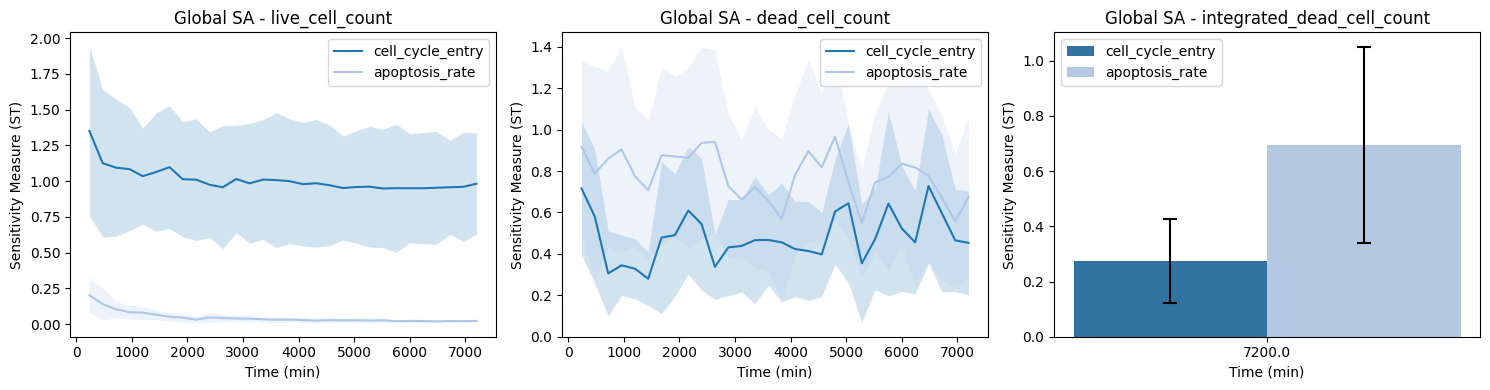

In [3]:
from uq_physicell.model_analysis import get_sa_results, plot_global_sa_results

sa_method = "Sobol Sensitivity Analysis"
qoi_names = list(qoi_funcs.keys())
sa_results, qoi_time_values = get_sa_results(db_file, qoi_names, df_mean_qois, sa_method)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax_id, qoi_name in enumerate(qoi_funcs.keys()):
    plot_global_sa_results(['cell_cycle_entry', 'apoptosis_rate'], sa_method, qoi_time_values, sa_results, qoi_name, 'ST' , axes[ax_id], 'ST_conf')
    axes[ax_id].set_title(f'Global SA - {qoi_name}')
    axes[ax_id].legend(loc='best')
plt.tight_layout() # This will automatically adjust spacing to prevent overlaps
plt.savefig('Global_SA_Results.svg', format='svg')

## Convergence evidence: Sobol ST vs. sample size N

SALib's Sobol/Saltelli sampler builds its design incrementally, so the first `N*(2*num_vars+2)` rows (in the original sampling order) of a design built for a larger `N` are *exactly* the design that would have been generated for that smaller `N` on its own (same seed). That lets us re-analyze prefixes of the existing 192-run database as if `N` had been 4, 8, 16, or 32 -- no new simulations needed -- to check whether ST has actually stabilized at the `N` used for the analysis above, rather than assuming it.

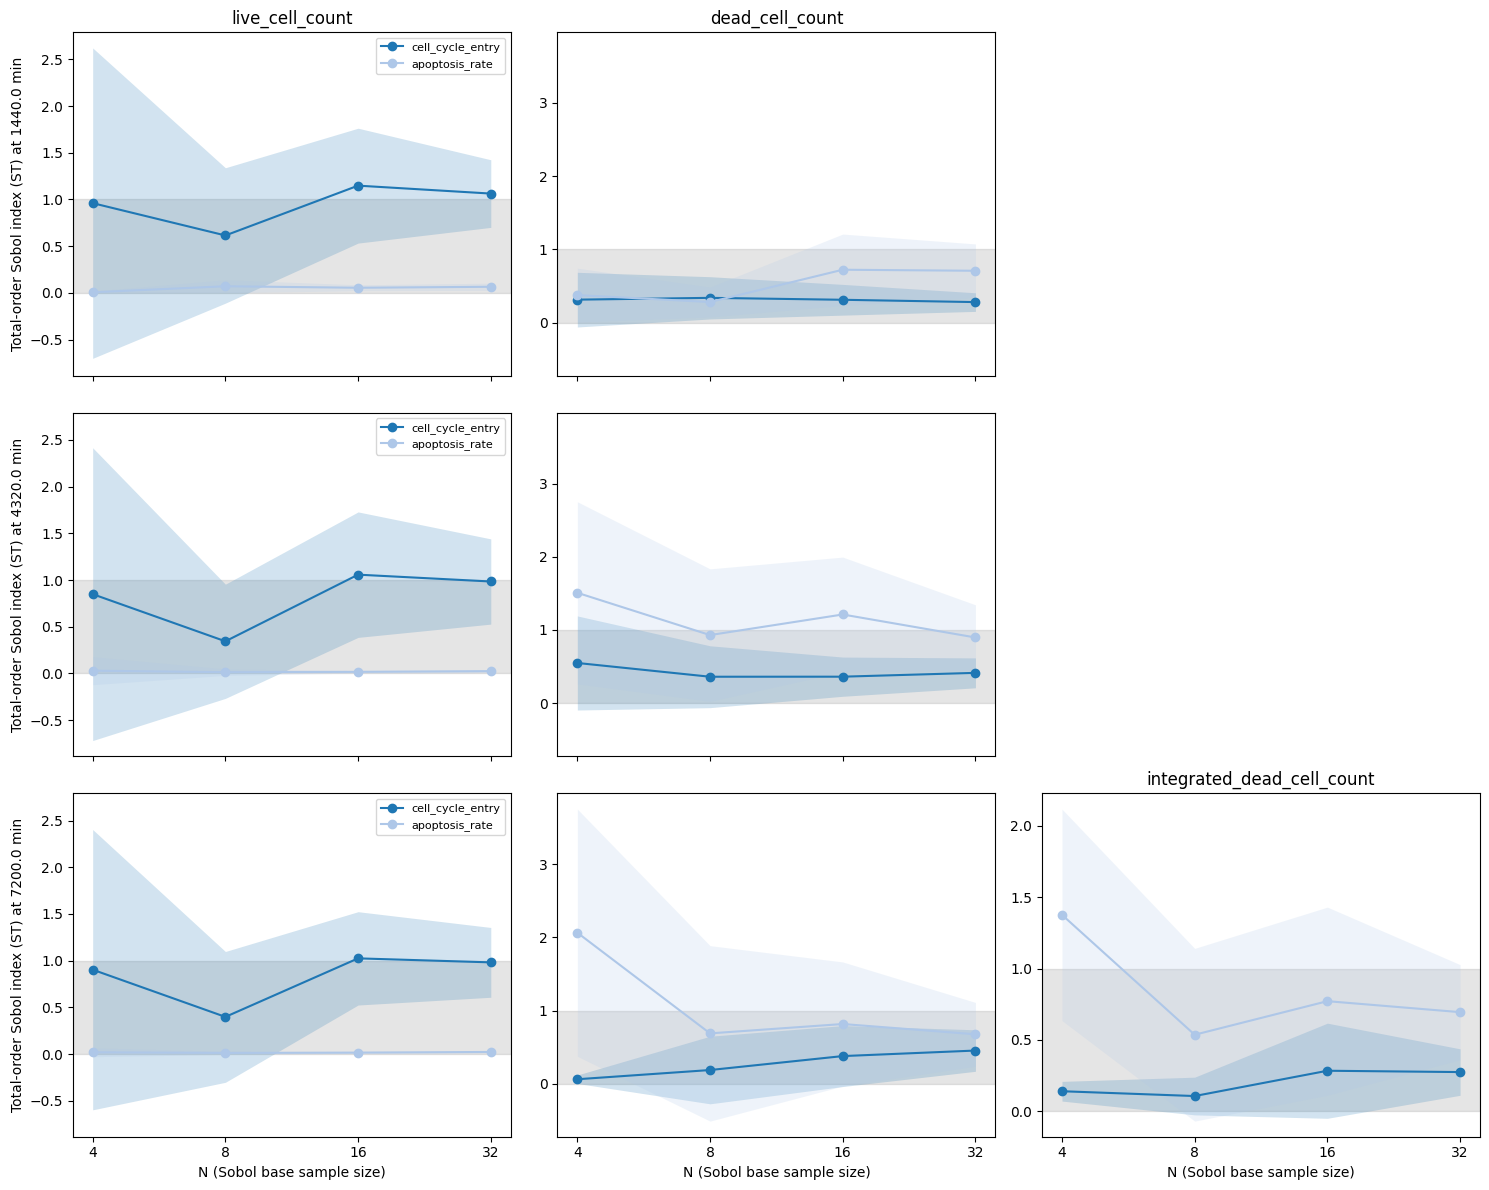

In [4]:
from uq_physicell.model_analysis import get_sobol_convergence, plot_sobol_convergence

N_values = [4, 8, 16, 32]
convergence_times = [1440.0, 4320.0, 7200.0]  # final simulated time (min); pick the time point you want to check
fig, axes = plt.subplots(len(convergence_times), len(qoi_names), figsize=(5 * len(qoi_names), 4*len(convergence_times)), sharex='col', sharey='col')
for i, time in enumerate(convergence_times):
    convergence = get_sobol_convergence(db_file, qoi_names, df_mean_qois, time, N_values)
    plot_sobol_convergence(N_values, convergence, qoi_names, ['cell_cycle_entry', 'apoptosis_rate'], axes[i])
    # Remove x-axis label for all but the last row
    if i != len(convergence_times) - 1 and len(axes) > 1:
        for ax in axes[i]:
            ax.set_xlabel('')  
    # Remove title for all but the first row
    if i != 0:
        for id_ax, ax in enumerate(axes[i]):
            if axes[0,id_ax].get_title():
                ax.set_title('')
    # Remove and rename y-axis label for all but the first column
    for j, ax in enumerate(axes[i]):
        if j != 0:
            ax.set_ylabel('')
        else:
            ax.set_ylabel(f'Total-order Sobol index (ST) at {time} min', fontsize=10)
plt.tight_layout()
plt.savefig(f'Global_SA_Convergence.svg', format='svg')

## Plot snapshots of some samples

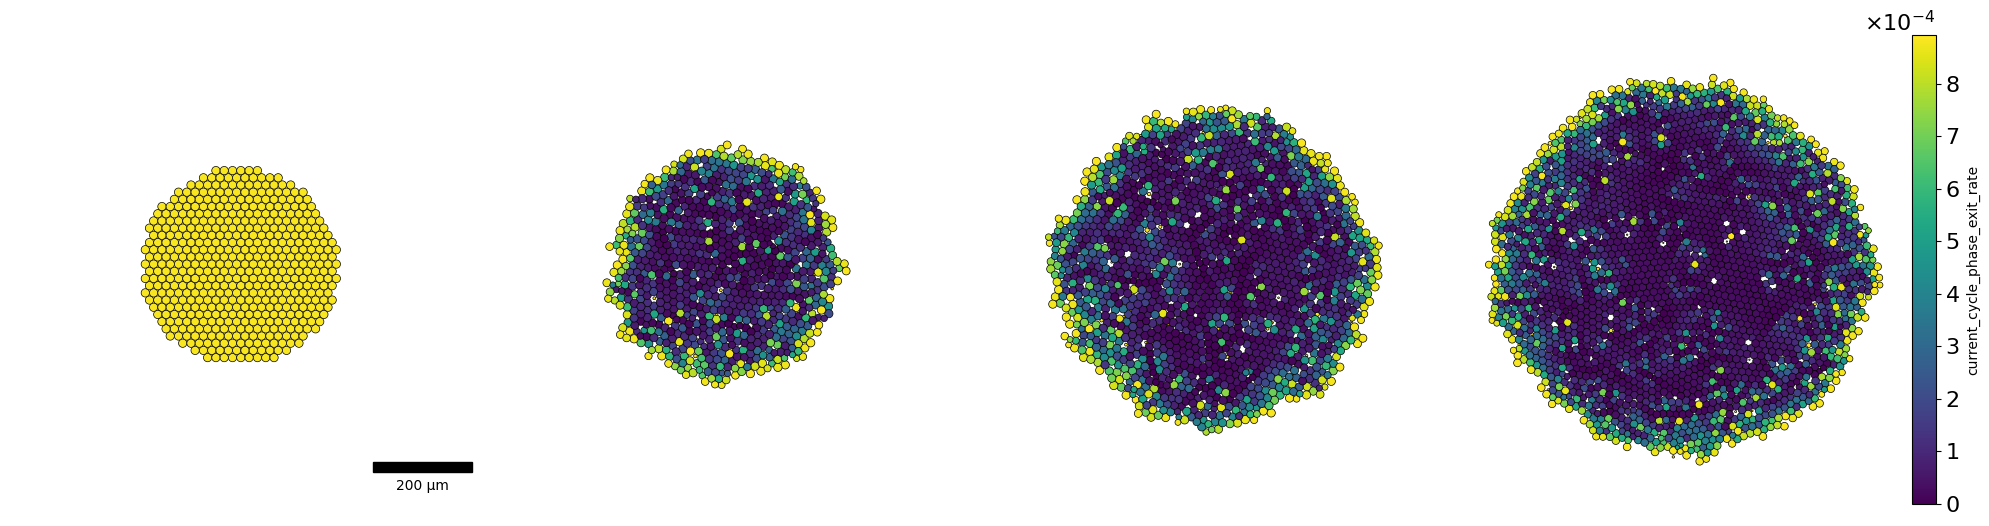

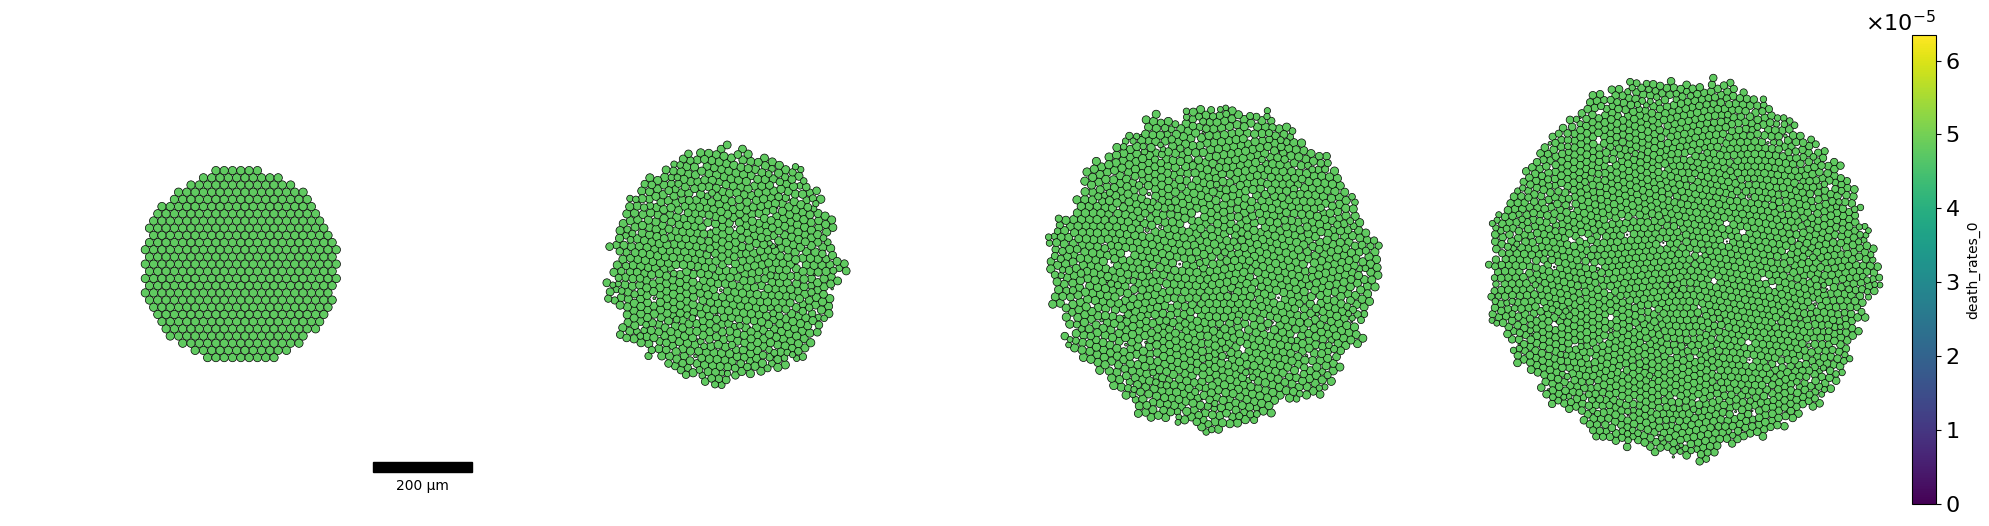

In [5]:
from uq_physicell.model_analysis import load_output, plot_cells_2D, load_samples
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd

def plot_snapshots(sample_id, replicate_id, feature, min_value=0, max_value=1):
    df_qois_data_selected = load_output(db_file, sample_ids=[int(sample_id)], replicate_ids=[replicate_id], load_data=True)
    mcds_ts = df_qois_data_selected[df_qois_data_selected['SampleID'] == sample_id].iloc[0]['Data']
    fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharex=True, sharey=True)
    ax_id = 0
    last_collection = None
    for i, mcds in enumerate(mcds_ts):
        if mcds.get_time() in [0,1440,4320,7200]: # Plot at specific time points
            df_cell = mcds.get_cell_df()
            last_collection = plot_cells_2D(df_cell, ax=axes[ax_id], scale_bar=True if (ax_id==0) else False, feature=feature, cmap='viridis', vmin=min_value, vmax=max_value)
            ax_id += 1
    cbar = fig.colorbar(last_collection, ax=axes[-1], fraction=0.05, pad=0.02)
    # Configure the formatter to use scientific notation
    formatter = ticker.ScalarFormatter(useMathText=True)
    formatter.set_scientific(True)
    formatter.set_powerlimits((-2, 2)) # Adjusts when sci-notation kicks in
    cbar.ax.tick_params(labelsize=16)               # tick labels
    cbar.ax.yaxis.get_offset_text().set_size(16)    # scientific notation text (e.g., ×10⁻³)
    cbar.ax.yaxis.set_major_formatter(formatter)
    cbar.set_label(feature)
    plt.tight_layout()
    plt.savefig(f'snapshot_{feature}_sample{sample_id}_replicate{replicate_id}.svg', format='svg')

# Identify the sample IDs with the maximum and minimum values for live and dead cell counts
max_live_cell_sample_id, _ = df_mean_qois['live_cell_count'].idxmax()
min_live_cell_sample_id, _ = df_mean_qois['live_cell_count'].idxmin()
max_dead_cell_sample_id, _ = df_mean_qois['integrated_dead_cell_count'].idxmax()
min_dead_cell_sample_id, _ = df_mean_qois['integrated_dead_cell_count'].idxmin()

# Extract parameters for the cmap limits
all_parameters = load_samples(db_file)
df_all_parameters = pd.DataFrame.from_dict(all_parameters, orient='index')
max_apoptosis_rate = df_all_parameters['apoptosis_rate'].max()
min_cell_cycle_entry = df_all_parameters['cell_cycle_entry'].min()

# Plot snapshots for the identified sample IDs and features of interest
plot_snapshots(max_live_cell_sample_id, replicate_id=0, feature='current_cycle_phase_exit_rate', max_value=1/min_cell_cycle_entry)
plot_snapshots(max_live_cell_sample_id, replicate_id=0, feature='death_rates_0', max_value=max_apoptosis_rate)
# plot_snapshots(min_live_cell_sample_id, replicate_id=0, feature='current_cycle_phase_exit_rate', max_value=1/min_cell_cycle_entry)
# plot_snapshots(max_dead_cell_sample_id, replicate_id=0, feature='death_rates_0', max_value=max_apoptosis_rate)
# plot_snapshots(min_dead_cell_sample_id, replicate_id=0, feature='death_rates_0', max_value=max_apoptosis_rate)